In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hyperillumination_utils import *
from astro_utils import *
from HItargets_utils import *
import os, contextlib, io
from dataclasses import replace
with contextlib.redirect_stdout(io.StringIO()):   # mute "no spidermanrc file detected"
    from simple_bias_analysis import overlay_planets

# Exoplanet Archive (to overlay known rocky planets on the a/Rs - Rp/Rs maps)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("K2-141 b")

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from K2-141 data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

In [3]:
# Basic Hyperillumination Stats
planet.summary(print_params=True, eff_wavelength_range=filter_lambda("MIRI/LRS"))

=== K2-141 b ===
    name = K2-141 b
  period = 0.2803244
    incl = 86.3
     ecc = 0.0
       w = 90.0
      r1 = 0.02037
      r2 = 1.0
       R = 2.292
  T2_eff = 4599.0
    a_AU = 0.00747
     T14 = 0.94
--- derived ---
rp = r1/r2           = 0.0204
a  = R/r2            = 2.292
terminator_penumbra  = 63.6 deg
terminator_nightside = 115.3 deg
fraction_illuminated = 71.4 %  (fully illuminated: 27.7 %, penumbra: 43.6 %)
substellar_boost     = 1.80147 % (insolation), 0.44736 % (temperature)
approx_occ_depth     = 207.3 ppm


### Comparison Nguyen et al. (2020)

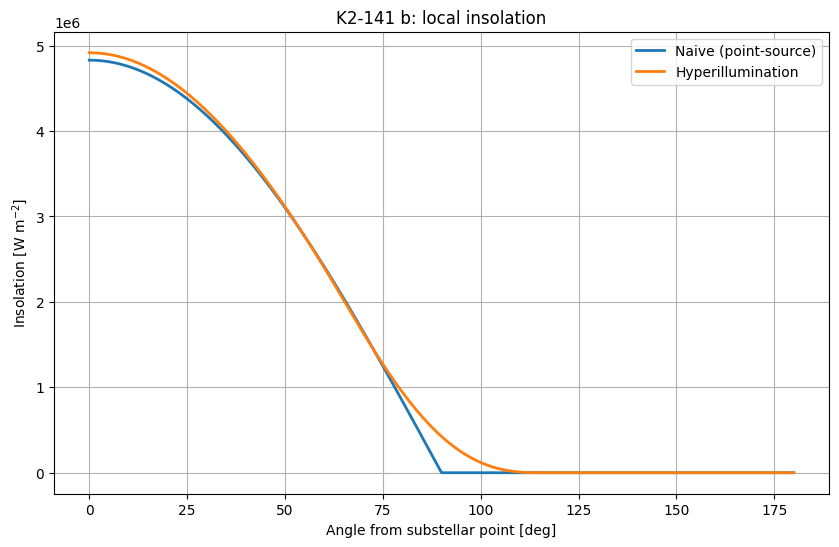

In [4]:
theta = np.linspace(0, 180, 1000)  # angle from substellar point [deg]
insol_naive = naive_insolation(np.radians(theta), planet)
insol_hyperillum = insolation_hyperillum(np.radians(theta), planet, u_B=u_B)

plt.figure(figsize=(10, 6))
plt.plot(theta, insol_naive, linewidth=2, label="Naive (point-source)")
plt.plot(theta, insol_hyperillum, linewidth=2, label="Hyperillumination")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title(f"{planet.name}: local insolation")
plt.legend()
plt.grid()

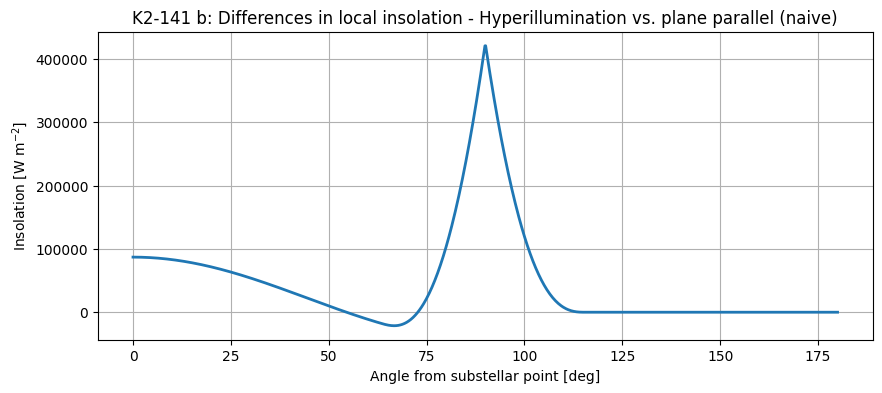

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(theta, insol_hyperillum-insol_naive, linewidth=2)
plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title(f"{planet.name}: Differences in local insolation - Hyperillumination vs. plane parallel (naive)")
plt.grid()
plt.show()

Luger 2022 & Carter 2024 predict that hyper-illumination models predict a hotter substellar point than the plane-parallel approximation.

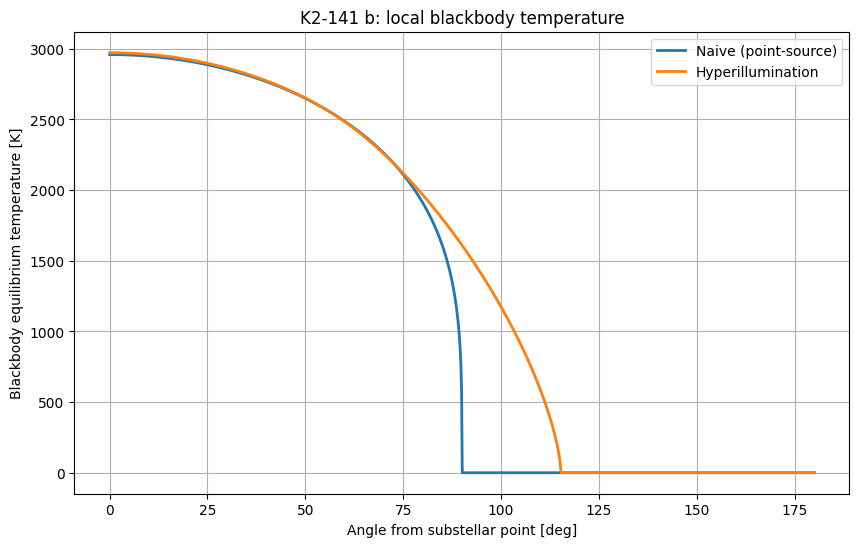

In [6]:
temp_naive = BBtemp_from_insolation(insol_naive)
temp_hyperillum = BBtemp_from_insolation(insol_hyperillum)

plt.figure(figsize=(10, 6))
plt.plot(theta, temp_naive, linewidth=2, label="Naive (point-source)")
plt.plot(theta, temp_hyperillum, linewidth=2, label="Hyperillumination")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel("Blackbody equilibrium temperature [K]")
plt.title(f"{planet.name}: local blackbody temperature")
plt.legend()
plt.grid()  

Temperature at 90° is around 1750K. The local BB spectrum peaks at around 1650nm. 
MIRI: 4.9 to 28.8 microns.

insolation_penumbra_mask runtime: 0.7274 s
insolation_penumbra_hyperillum runtime: 0.0011 s
insolation_penumbra_hyperillum_simpleint runtime: 0.9417 s
insolation_penumbra_hyperillum_approx runtime: 0.0001 s


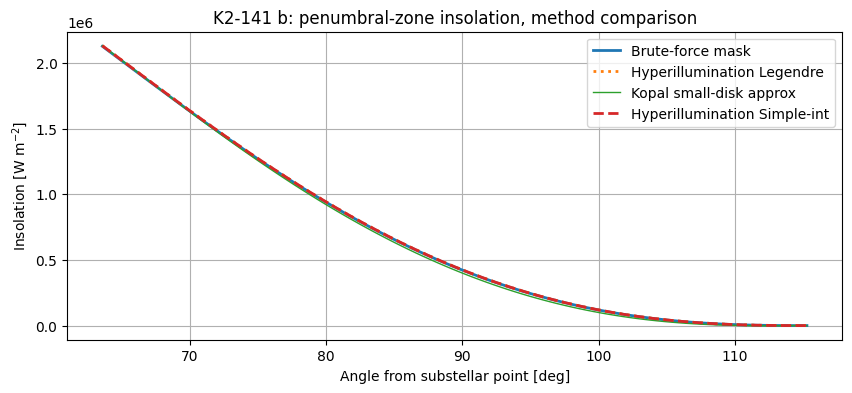

In [7]:
theta_pen = np.linspace(planet.terminator_penumbra(unit="deg"), planet.terminator_nightside(unit="deg"), 100)

insol_mask = insolation_penumbra_mask(np.radians(theta_pen), planet, runtime=True, u_B=u_B)
insol_hyperillum_legendre = insolation_penumbra_hyperillum(np.radians(theta_pen), planet, runtime=True, u_B=u_B)
insol_hyperillum_simpleint = insolation_penumbra_hyperillum_simpleint(np.radians(theta_pen), planet, runtime=True, u_B=u_B)
insol_hyperillum_approx = insolation_penumbra_hyperillum_approx(np.radians(theta_pen), planet, runtime=True, u_B=u_B)

plt.figure(figsize=(10, 4))
plt.plot(theta_pen, insol_mask, linewidth=2, label="Brute-force mask")
plt.plot(theta_pen, insol_hyperillum_legendre, linewidth=2, linestyle=":", label="Hyperillumination Legendre")
plt.plot(theta_pen, insol_hyperillum_approx, linewidth=1, label="Kopal small-disk approx")
plt.plot(theta_pen, insol_hyperillum_simpleint, linewidth=2, linestyle="--", label="Hyperillumination Simple-int")


plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title(f"{planet.name}: penumbral-zone insolation, method comparison")
plt.legend()
plt.grid()

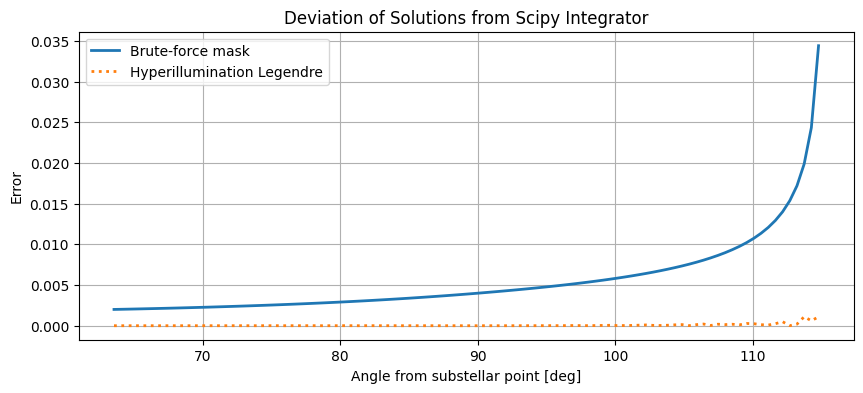

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(theta_pen, np.abs(1-insol_mask/insol_hyperillum_simpleint), linewidth=2, label="Brute-force mask")
plt.plot(theta_pen, np.abs(1-insol_hyperillum_legendre/insol_hyperillum_simpleint), linewidth=2, linestyle=":", label="Hyperillumination Legendre")
#plt.plot(theta_pen, np.abs(1-insol_hyperillum_approx/insol_hyperillum_simpleint), linewidth=1, label="Kopal small-disk approx")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel("Error")
plt.title("Deviation of Solutions from Scipy Integrator")
plt.legend()
plt.grid()

### Illuminated Fractions of Exoplanet

In [9]:
planet.fraction_illuminated("extra")

{'fully illuminated': 0.27740619546247813, 'penumbra': 0.43630017452006986}

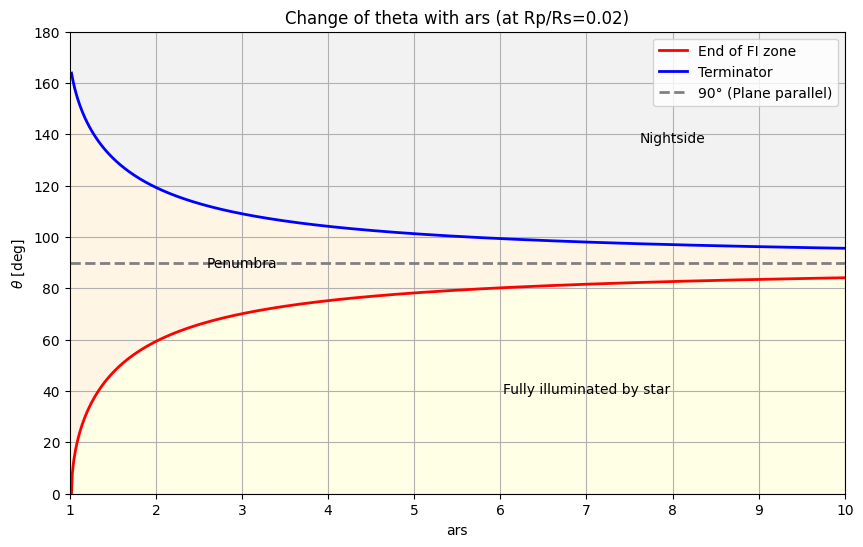

In [10]:
rprs=0.02 # r1/r2
ars=np.linspace(1+rprs,10, 1000) # R/r2
theta_inner = np.degrees(np.arccos((rprs+1)/ars))
theta_outer = np.degrees(np.arccos((rprs-1)/ars))

plt.figure(figsize=(10, 6))
plt.fill_between(ars, 0, theta_inner, color="yellow", alpha=0.1, linewidth=0, zorder=0)
plt.fill_between(ars, theta_inner, theta_outer, color="orange", alpha=0.1, linewidth=0, zorder=0)
plt.fill_between(ars, theta_outer, 180, color="grey", alpha=0.1, linewidth=0, zorder=0)

plt.text(7, np.interp(7, ars, theta_inner)/2, "Fully illuminated by star", ha="center", va="center", fontsize=10)
plt.text(3, (np.interp(3, ars, theta_inner)+np.interp(3, ars, theta_outer))/2, "Penumbra", ha="center", va="center", fontsize=10)
plt.text(8, (np.interp(8, ars, theta_outer)+180)/2, "Nightside", ha="center", va="center", fontsize=10)

plt.plot(ars, theta_inner, label="End of FI zone", color="red", linewidth=2)
plt.plot(ars, theta_outer, label="Terminator", color="blue", linewidth=2)
plt.axhline(90, linestyle="--", color="grey", label="90° (Plane parallel)", linewidth=2)

plt.title("Change of theta with ars (at Rp/Rs=0.02)")
plt.ylabel(r"$\theta$ [deg]")
plt.xlabel("ars")
plt.xlim([1, 10])
plt.ylim([0, 180])
plt.legend()
plt.grid()
plt.show()

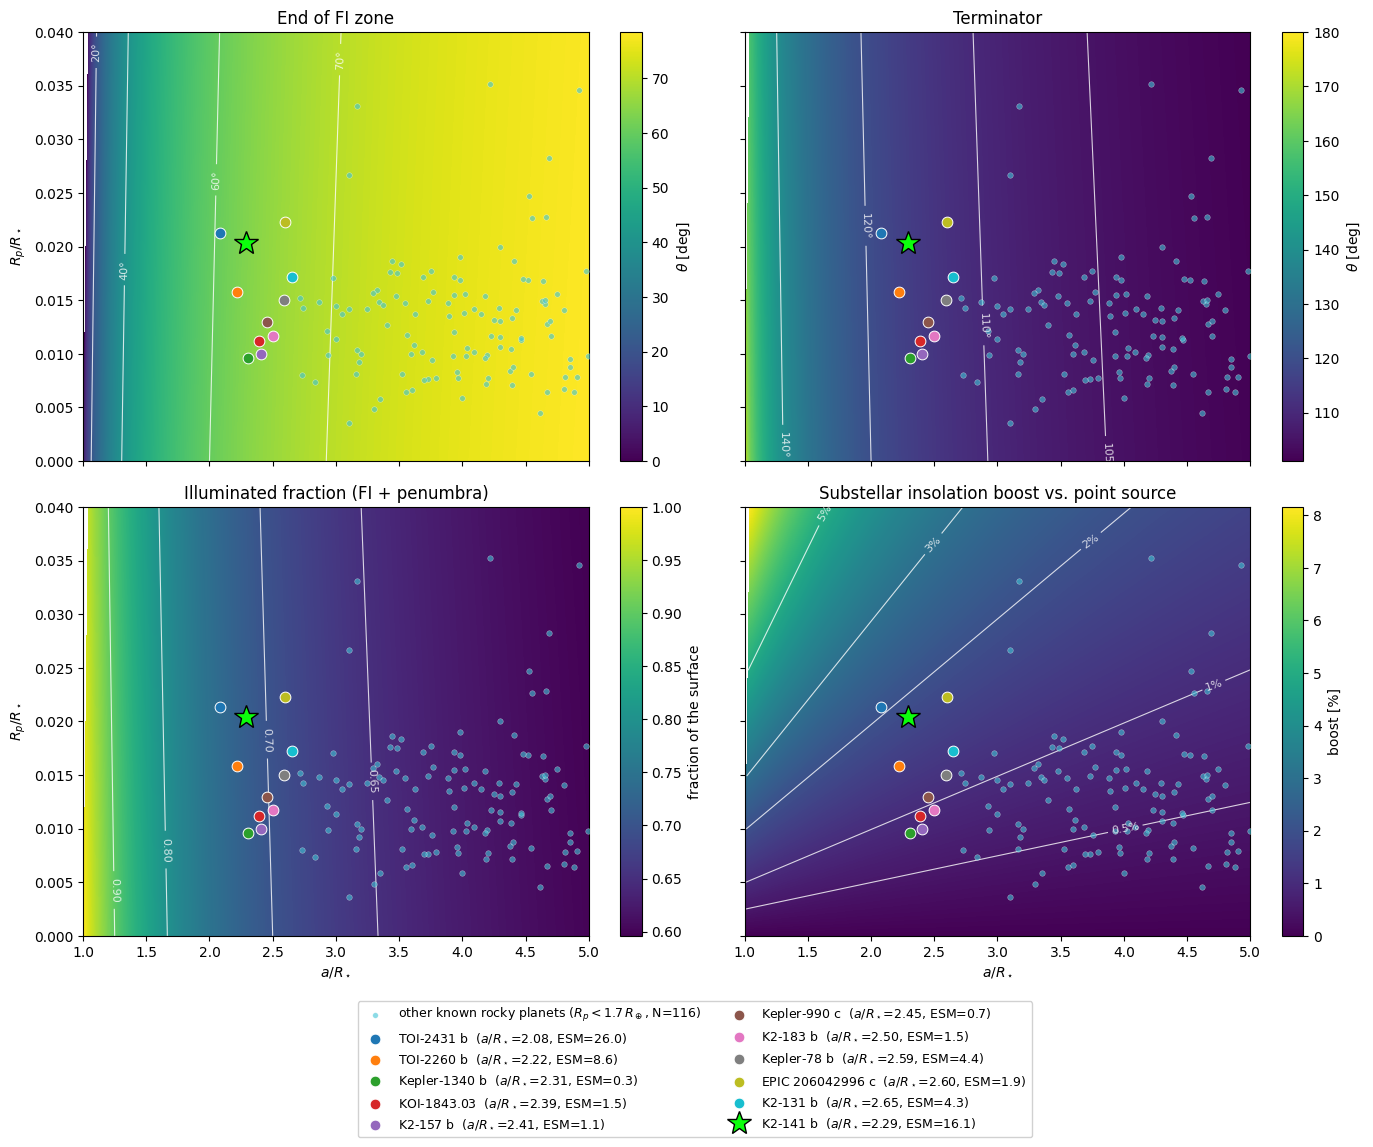

In [11]:
rprs_grid = np.linspace(0., 0.04, 1000)   # r1/r2
ars_grid = np.linspace(1., 5., 1000)    # R/r2
RPRS, ARS = np.meshgrid(rprs_grid, ars_grid, indexing="ij")
valid = ARS >= 1. + RPRS                  # otherwise the planet overlaps the star

# The whole grid as ONE PlanetParams with array-valued r1, R (r2 = 1): the class methods are elementwise, so the maps use exactly the same definitions as for a single planet
grid_planet = replace(planet, r1=RPRS, r2=1., R=ARS)
with np.errstate(invalid="ignore", divide="ignore"):
    maps = [
        (grid_planet.terminator_penumbra(unit="deg"),   "End of FI zone",                             r"$\theta$ [deg]",   [20, 40, 60, 70],     "%d°"),
        (grid_planet.terminator_nightside(unit="deg"),  "Terminator",                                 r"$\theta$ [deg]",   [105, 110, 120, 140], "%d°"),
        (grid_planet.fraction_illuminated(),            "Illuminated fraction (FI + penumbra)",       "fraction of the surface", [0.65, 0.7, 0.8, 0.9], "%.2f"),
        (100. * grid_planet.substellar_boost(),         "Substellar insolation boost vs. point source", "boost [%]",     [0.5, 1, 2, 3, 5],    "%g%%"),
    ]

fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
for ax, (z, title, clabel, levels, fmt) in zip(axs.flat, maps):
    z = np.where(valid, z, np.nan)
    im = ax.pcolormesh(ars_grid, rprs_grid, z, shading="auto", cmap="viridis")
    cs = ax.contour(ars_grid, rprs_grid, z, levels=levels, colors="w", linewidths=.8, alpha=.8)
    ax.clabel(cs, fmt=fmt, fontsize=8, inline_spacing=3)
    fig.colorbar(im, ax=ax, label=clabel)
    overlay_planets(AGG, ax, "pl_ratror", (rprs_grid[0], rprs_grid[-1]), a_rs_lim=(ars_grid[0], ars_grid[-1]), target=planet)
    ax.set_title(title)
    ax.set_xlim(ars_grid[0], ars_grid[-1]); ax.set_ylim(rprs_grid[0], rprs_grid[-1])
for ax in axs[1]: ax.set_xlabel(r"$a/R_\star$")
for ax in axs[:, 0]: ax.set_ylabel(r"$R_p/R_\star$")

# one shared legend: the 10 rocky planets with the smallest a/Rs are named, the rest are background dots
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=9, framealpha=.9)
plt.tight_layout()
plt.show()

### Convergence to Naive model
With growing a/Rs the star shrinks towards a point source, so the hyper-illuminated insolation profile should converge to the naive (plane-parallel) cosine profile. The naive curve is normalized to its own maximum; each hyperillumination curve is divided by the naive maximum at the same a/Rs, so its peak directly shows the substellar boost (1 + `substellar_boost`) and the penumbra extends past 90°. The normalized naive curve is the same for every a/Rs, so a single one suffices.

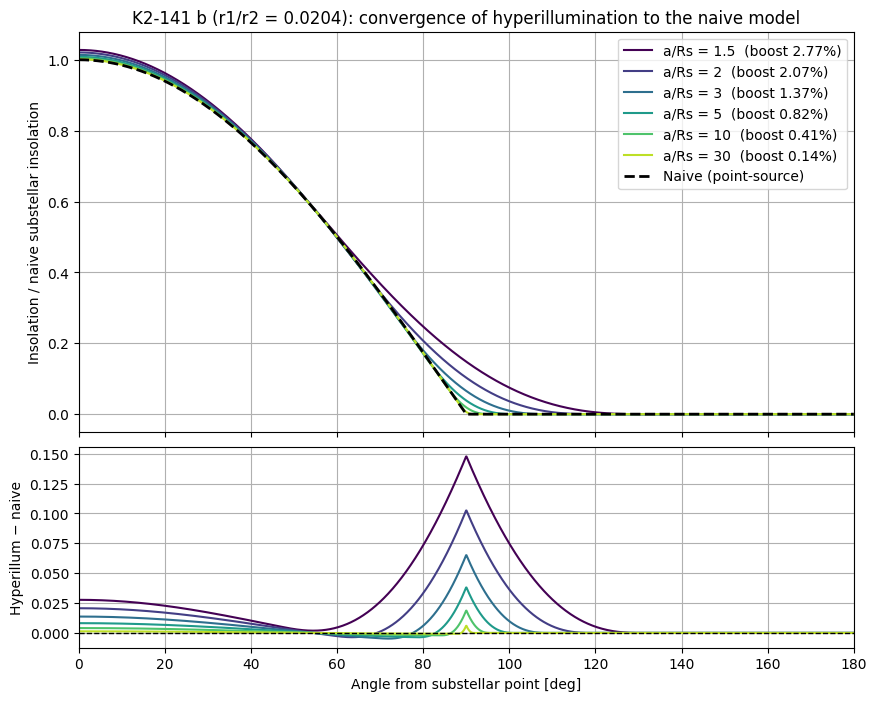

In [12]:
ars_values = [1.5, 2, 3, 5, 10, 30]                 # R/r2 (planet's own value: planet.R/planet.r2)
theta = np.linspace(0, 180, 2000)                   # angle from substellar point [deg]
gamma1 = np.radians(theta)

# Normalized naive profile (identical for all a/Rs: cos(gamma1) clipped at 90 deg)
insol_naive_norm = naive_insolation(gamma1, planet) / naive_insolation(gamma1, planet).max()

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(ars_values)))

for ars, color in zip(ars_values, colors):
    p = replace(planet, R=ars * planet.r2)          # keep r1, r2 of "planet", only change the orbital distance
    insol_hyper_norm = insolation_hyperillum(gamma1, p, u_B=u_B) / naive_insolation(gamma1, p).max()
    ax_top.plot(theta, insol_hyper_norm, color=color, linewidth=1.5, label=f"a/Rs = {ars:g}  (boost {100*p.substellar_boost():.2f}%)")
    ax_bot.plot(theta, insol_hyper_norm - insol_naive_norm, color=color, linewidth=1.5)

ax_top.plot(theta, insol_naive_norm, color="black", linestyle="--", linewidth=2, label="Naive (point-source)")
ax_bot.axhline(0, color="black", linestyle="--", linewidth=1)

ax_top.set_ylabel("Insolation / naive substellar insolation")
ax_top.set_title(f"{planet.name} (r1/r2 = {planet.r1/planet.r2:.4f}): convergence of hyperillumination to the naive model")
ax_top.legend()
ax_top.grid()

ax_bot.set_xlabel("Angle from substellar point [deg]")
ax_bot.set_ylabel("Hyperillum − naive")
ax_bot.set_xlim(0, 180)
ax_bot.grid()
plt.show()

### Planetary Insolation-/Heatmaps

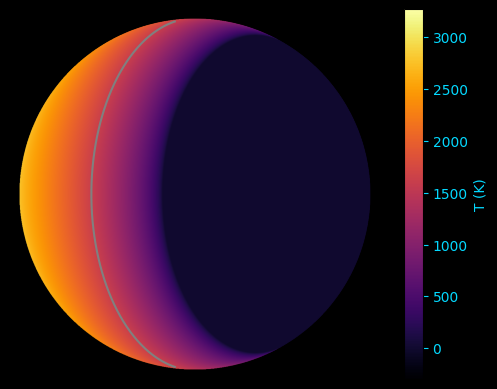

In [13]:
phase = 0.35
ax=plot_insolmap(phase, planet, insolation_model="hyperillum", terminator=True, unit="temperature", u_B=u_B)

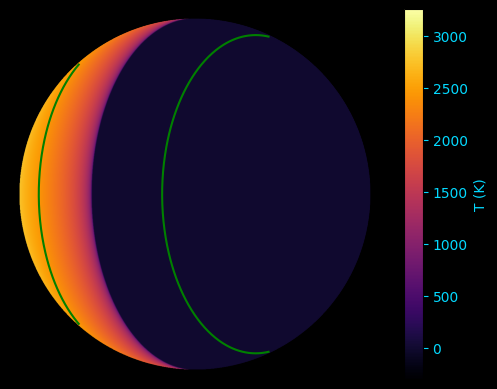

In [14]:
phase = 0.35
ax=plot_insolmap(phase, planet, insolation_model="naive", show_penumbra="both", unit="temperature", u_B=u_B)

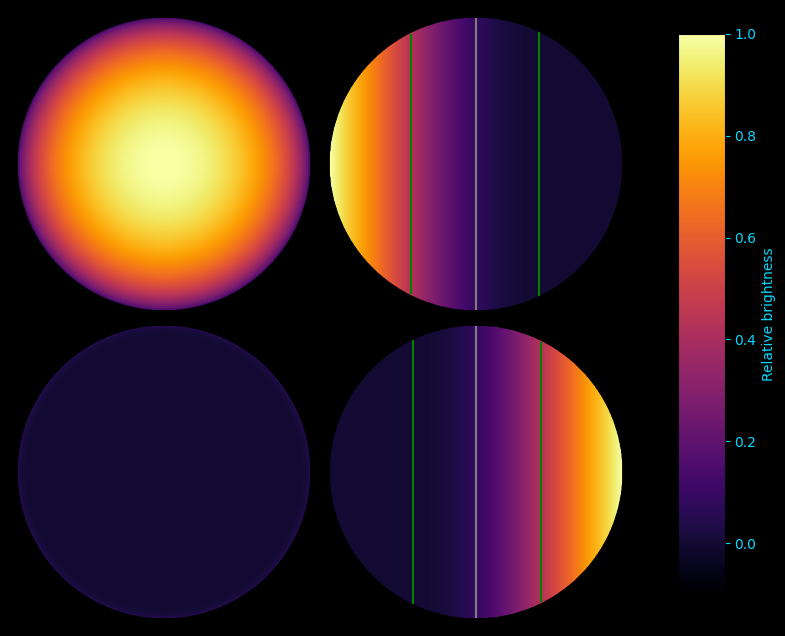

In [15]:
ax=plot_quad_insolmap(planet, insolation_model="hyperillum", terminator=True, show_penumbra="both", unit="flux", u_B=u_B)

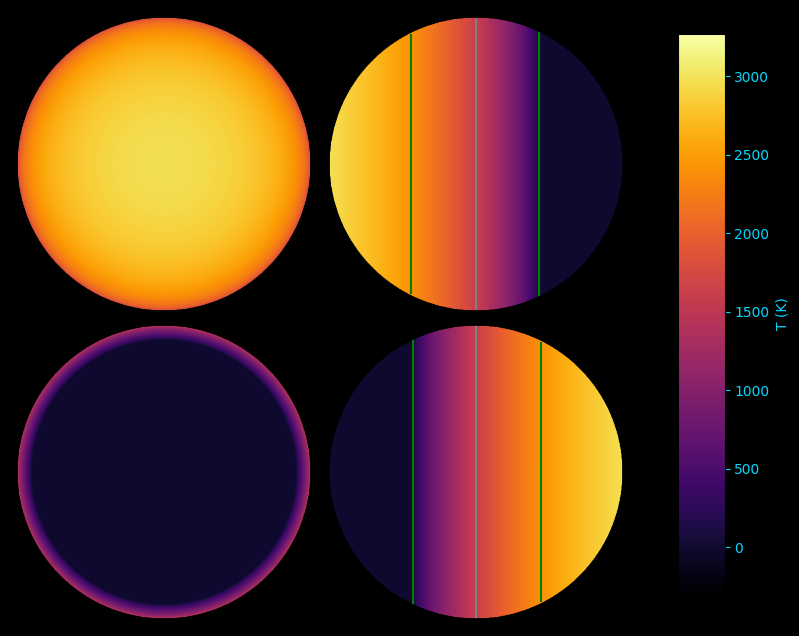

In [16]:
ax=plot_quad_insolmap(planet, insolation_model="hyperillum", terminator=True, show_penumbra="both", unit="temperature", u_B=u_B)

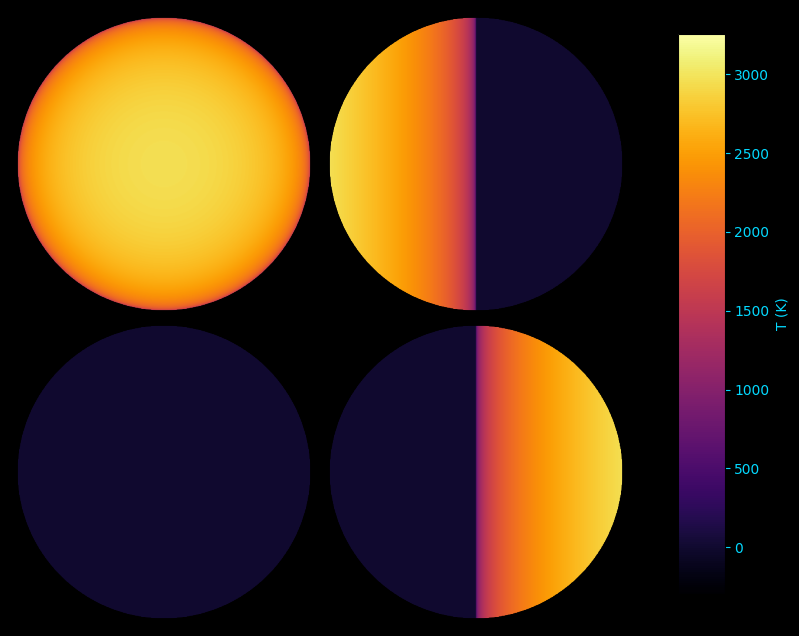

In [17]:
ax=plot_quad_insolmap(planet, insolation_model="naive", unit="temperature", u_B=u_B)

In [18]:
# from IPython.display import Image
#
# animation_insolmap(planet, insolation_model="hyperillum", terminator=True, unit="temperature", filename="tempmap_hyperillum")
# animation_insolmap(planet, insolation_model="naive", terminator=False, unit="temperature", filename="tempmap_naive")
# animation_insolmap(planet, insolation_model="hyperillum", terminator=True, unit="flux", filename="fluxmap_hyperillum")
# animation_insolmap(planet, insolation_model="naive", terminator=False, unit="flux", filename="fluxmap_naive")

In [19]:
#Image(filename="tempmap_hyperillum.gif")

In [20]:
#Image(filename="tempmap_naive.gif")

In [21]:
#Image(filename="fluxmap_hyperillum.gif")

In [22]:
#Image(filename="fluxmap_naive.gif")